In [26]:
# ============================================================
# CELL 1: ENVIRONMENT AND GPU VERIFICATION
# ============================================================

import os
import sys
import random
import json
import time
import math
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 60)
print("ENVIRONMENT")
print("=" * 60)

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

print("=" * 60)

ENVIRONMENT
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA available: True
Device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB


In [27]:
# ============================================================
# CELL 2: LOCATE INPUT FILES
# ============================================================

from pathlib import Path

KAGGLE_INPUT = Path("/kaggle/input")

EXPECTED_FILES = [
    "training_annual.npz",
    "validation_annual.npz",
    "testing_annual.npz",
    "annual_forecasting_metadata.json",
    "static_spatial_graph_verified.pt"
]

found_files = {}

for filename in EXPECTED_FILES:
    matches = list(KAGGLE_INPUT.rglob(filename))

    if len(matches) > 0:
        found_files[filename] = matches[0]
        print(f"FOUND: {filename}")
        print(f"      {matches[0]}")
    else:
        print(f"NOT FOUND: {filename}")

print("\n" + "=" * 60)

if len(found_files) != len(EXPECTED_FILES):
    print("WARNING: Some files were not found.")
    print("Please verify that the Kaggle dataset is attached.")
else:
    print("All expected files found.")

FOUND: training_annual.npz
      /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/training_annual.npz
FOUND: validation_annual.npz
      /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/validation_annual.npz
FOUND: testing_annual.npz
      /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/testing_annual.npz
FOUND: annual_forecasting_metadata.json
      /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/annual_forecasting_metadata.json
FOUND: static_spatial_graph_verified.pt
      /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/static_spatial_graph_verified.pt

All expected files found.


In [28]:
# ============================================================
# CELL 3: INSPECT DATA FILES
# ============================================================

for split_name in ["training_annual.npz",
                  "validation_annual.npz",
                  "testing_annual.npz"]:

    file_path = found_files[split_name]

    print("\n" + "=" * 70)
    print(split_name)
    print("=" * 70)

    data = np.load(file_path, allow_pickle=False)

    print("Keys:", data.files)

    for key in data.files:
        arr = data[key]

        print(
            f"{key:20s}",
            "Shape:", arr.shape,
            "Dtype:", arr.dtype
        )

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

metadata_path = found_files["annual_forecasting_metadata.json"]

with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("\n" + "=" * 70)
print("METADATA")
print("=" * 70)

print(json.dumps(metadata, indent=2))


training_annual.npz
Keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
X                    Shape: (8, 10, 5040, 4) Dtype: float32
Y                    Shape: (8, 5040, 2) Dtype: float32
Y_mask               Shape: (8, 5040, 2) Dtype: bool
input_indices        Shape: (8, 10) Dtype: int64
target_indices       Shape: (8,) Dtype: int64
target_years         Shape: (8,) Dtype: int64

validation_annual.npz
Keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
X                    Shape: (6, 10, 5040, 4) Dtype: float32
Y                    Shape: (6, 5040, 2) Dtype: float32
Y_mask               Shape: (6, 5040, 2) Dtype: bool
input_indices        Shape: (6, 10) Dtype: int64
target_indices       Shape: (6,) Dtype: int64
target_years         Shape: (6,) Dtype: int64

testing_annual.npz
Keys: ['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years']
X                    Shape: (2, 10, 5040, 4) Dtype: float32
Y                    S

In [29]:
# ============================================================
# CELL 4: LOAD TRAIN / VALIDATION / TEST DATA
# ============================================================

def load_npz_split(file_path):

    data = np.load(file_path, allow_pickle=False)

    result = {}

    for key in data.files:
        result[key] = data[key]

    return result


train_data = load_npz_split(found_files["training_annual.npz"])
val_data   = load_npz_split(found_files["validation_annual.npz"])
test_data  = load_npz_split(found_files["testing_annual.npz"])

print("Training keys:", train_data.keys())
print("Validation keys:", val_data.keys())
print("Testing keys:", test_data.keys())

Training keys: dict_keys(['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years'])
Validation keys: dict_keys(['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years'])
Testing keys: dict_keys(['X', 'Y', 'Y_mask', 'input_indices', 'target_indices', 'target_years'])


In [30]:
# ============================================================
# CELL 5: DATA VALIDATION
# ============================================================

def inspect_split(name, data):

    print("\n" + "=" * 70)
    print(name.upper())
    print("=" * 70)

    for key, value in data.items():

        print(
            key,
            "| Shape:", value.shape,
            "| Dtype:", value.dtype
        )

        if np.issubdtype(value.dtype, np.number):

            print("  NaN count:", np.isnan(value).sum())
            print("  Inf count:", np.isinf(value).sum())

            if np.isfinite(value).any():
                print(
                    "  Min:", np.nanmin(value),
                    "| Max:", np.nanmax(value)
                )


inspect_split("Training", train_data)
inspect_split("Validation", val_data)
inspect_split("Testing", test_data)


TRAINING
X | Shape: (8, 10, 5040, 4) | Dtype: float32
  NaN count: 0
  Inf count: 0
  Min: -4.1639476 | Max: 13.793045
Y | Shape: (8, 5040, 2) | Dtype: float32
  NaN count: 7189
  Inf count: 0
  Min: 0.0 | Max: 35.0763
Y_mask | Shape: (8, 5040, 2) | Dtype: bool
input_indices | Shape: (8, 10) | Dtype: int64
  NaN count: 0
  Inf count: 0
  Min: 0 | Max: 16
target_indices | Shape: (8,) | Dtype: int64
  NaN count: 0
  Inf count: 0
  Min: 10 | Max: 17
target_years | Shape: (8,) | Dtype: int64
  NaN count: 0
  Inf count: 0
  Min: 2010 | Max: 2017

VALIDATION
X | Shape: (6, 10, 5040, 4) | Dtype: float32
  NaN count: 0
  Inf count: 0
  Min: -4.1248083 | Max: 14.607722
Y | Shape: (6, 5040, 2) | Dtype: float32
  NaN count: 5437
  Inf count: 0
  Min: 0.037230708 | Max: 34.931297
Y_mask | Shape: (6, 5040, 2) | Dtype: bool
input_indices | Shape: (6, 10) | Dtype: int64
  NaN count: 0
  Inf count: 0
  Min: 8 | Max: 22
target_indices | Shape: (6,) | Dtype: int64
  NaN count: 0
  Inf count: 0
  Min: 1

In [31]:
!pip install torch_geometric 

In [32]:
# ============================================================
# CELL 6: LOAD AND VERIFY SPATIAL GRAPH
# ============================================================

graph_path = found_files["static_spatial_graph_verified.pt"]

print("Graph file:", graph_path)

# PyTorch 2.6+ uses weights_only=True by default.
# This file is your own verified graph artifact.
graph_object = torch.load(
    graph_path,
    map_location="cpu",
    weights_only=False
)

print("\nGraph object type:", type(graph_object))

print("\nGraph object:")
print(graph_object)

print("\nGraph attributes:")

if hasattr(graph_object, "__dict__"):
    for key, value in graph_object.__dict__.items():

        if torch.is_tensor(value):
            print(
                key,
                "| Shape:", tuple(value.shape),
                "| Dtype:", value.dtype
            )
        else:
            print(key, "|", type(value), "|", value)

Graph file: /kaggle/input/datasets/drrajgauravmishra/spatiotemporal-gnn-kaggle-data/Spatiotemporal_GNN_Kaggle_Data/static_spatial_graph_verified.pt

Graph object type: <class 'torch_geometric.data.data.Data'>

Graph object:
Data(edge_index=[2, 40320], num_nodes=5040)

Graph attributes:
_edge_attr_cls | <class 'type'> | <class 'torch_geometric.data.data.DataEdgeAttr'>
_tensor_attr_cls | <class 'type'> | <class 'torch_geometric.data.data.DataTensorAttr'>
_store | <class 'torch_geometric.data.storage.GlobalStorage'> | {'edge_index': tensor([[   0,    0,    0,  ..., 5039, 5039, 5039],
        [ 126,    2,  136,  ..., 4965, 5032, 5036]]), 'num_nodes': 5040}


In [33]:
# ============================================================
# CELL 7: EXTRACT GRAPH STRUCTURE
# ============================================================

# ------------------------------------------------------------
# Extract edge_index
# ------------------------------------------------------------

if hasattr(graph_object, "edge_index"):

    edge_index = graph_object.edge_index

elif isinstance(graph_object, dict):

    if "edge_index" in graph_object:
        edge_index = graph_object["edge_index"]

    elif "edges" in graph_object:
        edge_index = graph_object["edges"]

    else:
        raise KeyError(
            "Could not find edge_index or edges in graph dictionary."
        )

else:

    raise TypeError(
        f"Unsupported graph object type: {type(graph_object)}"
    )


# ------------------------------------------------------------
# Extract edge weights if available
# ------------------------------------------------------------

if hasattr(graph_object, "edge_weight"):

    edge_weight = graph_object.edge_weight

elif isinstance(graph_object, dict) and "edge_weight" in graph_object:

    edge_weight = graph_object["edge_weight"]

else:

    edge_weight = None


# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

edge_index = torch.as_tensor(edge_index).long()

print("Edge index shape:", edge_index.shape)
print("Edge index dtype:", edge_index.dtype)

if edge_weight is not None:
    edge_weight = torch.as_tensor(edge_weight)
    print("Edge weight shape:", edge_weight.shape)
else:
    print("Edge weights: None")

print("Number of nodes expected:", metadata["number_of_nodes"])
print("Number of edges:", edge_index.shape[1])

print("Minimum node index:", edge_index.min().item())
print("Maximum node index:", edge_index.max().item())

assert edge_index.shape[0] == 2
assert edge_index.shape[1] == metadata["graph"]["number_of_directed_edges"]
assert edge_index.min().item() >= 0
assert edge_index.max().item() < metadata["number_of_nodes"]

print("\nGraph structural verification passed.")

Edge index shape: torch.Size([2, 40320])
Edge index dtype: torch.int64
Edge weights: None
Number of nodes expected: 5040
Number of edges: 40320
Minimum node index: 0
Maximum node index: 5039

Graph structural verification passed.


Number of nodes: 5040
Number of edges: 40320

Degree statistics:
Minimum degree: 2
Maximum degree: 14
Mean degree: 8.0
Median degree: 8.0

Number of self-loops: 0
Unique edges: 40320
Duplicate edges: 0
Reciprocal edge fraction: 0.9673611111111111


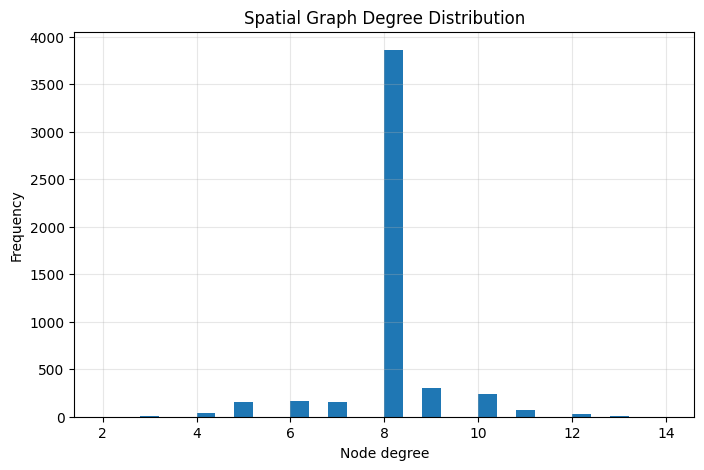

In [34]:
# ============================================================
# CELL 8: GRAPH QUALITY CHECKS
# ============================================================

num_nodes = metadata["number_of_nodes"]

src = edge_index[0]
dst = edge_index[1]

# ------------------------------------------------------------
# Degree statistics
# ------------------------------------------------------------

degree = torch.bincount(dst, minlength=num_nodes)

print("Number of nodes:", num_nodes)
print("Number of edges:", edge_index.shape[1])

print("\nDegree statistics:")
print("Minimum degree:", degree.min().item())
print("Maximum degree:", degree.max().item())
print("Mean degree:", degree.float().mean().item())
print("Median degree:", degree.float().median().item())

# ------------------------------------------------------------
# Self-loops
# ------------------------------------------------------------

self_loop_mask = src == dst

print("\nNumber of self-loops:", self_loop_mask.sum().item())

# ------------------------------------------------------------
# Duplicate edges
# ------------------------------------------------------------

edge_pairs = torch.stack([src, dst], dim=1)

unique_edges = torch.unique(edge_pairs, dim=0)

print("Unique edges:", unique_edges.shape[0])
print("Duplicate edges:", edge_pairs.shape[0] - unique_edges.shape[0])

# ------------------------------------------------------------
# Directed edge reciprocity
# ------------------------------------------------------------

edge_set = set(
    zip(src.tolist(), dst.tolist())
)

reciprocal_count = sum(
    (v, u) in edge_set
    for u, v in edge_set
)

print(
    "Reciprocal edge fraction:",
    reciprocal_count / max(len(edge_set), 1)
)

# ------------------------------------------------------------
# Visualize degree distribution
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.hist(degree.numpy(), bins=30)

plt.xlabel("Node degree")
plt.ylabel("Frequency")
plt.title("Spatial Graph Degree Distribution")

plt.grid(alpha=0.3)
plt.show()

In [35]:
# ============================================================
# CELL 9: PREPARE SPARSE SPATIAL GRAPH
# ============================================================

def prepare_sparse_graph(edge_index, num_nodes, device):

    edge_index = edge_index.long()

    # --------------------------------------------------------
    # Add self-loops
    # --------------------------------------------------------

    self_loops = torch.arange(num_nodes)

    self_loop_edges = torch.stack(
        [self_loops, self_loops],
        dim=0
    )

    edge_index = torch.cat(
        [edge_index, self_loop_edges],
        dim=1
    )

    # --------------------------------------------------------
    # Remove duplicate edges
    # --------------------------------------------------------

    edge_index = torch.unique(
        edge_index,
        dim=1
    )

    # --------------------------------------------------------
    # Build adjacency matrix
    # --------------------------------------------------------

    values = torch.ones(
        edge_index.shape[1],
        dtype=torch.float32
    )

    adjacency = torch.sparse_coo_tensor(
        edge_index,
        values,
        size=(num_nodes, num_nodes)
    ).coalesce()

    # --------------------------------------------------------
    # Symmetric normalization
    # A_hat = D^(-1/2) A D^(-1/2)
    # --------------------------------------------------------

    indices = adjacency.indices()
    values = adjacency.values()

    row = indices[0]
    col = indices[1]

    degree = torch.zeros(num_nodes)

    degree.index_add_(
        0,
        row,
        values
    )

    degree_inv_sqrt = degree.pow(-0.5)

    degree_inv_sqrt[
        torch.isinf(degree_inv_sqrt)
    ] = 0.0

    normalized_values = (
        degree_inv_sqrt[row]
        * values
        * degree_inv_sqrt[col]
    )

    normalized_adjacency = torch.sparse_coo_tensor(
        indices,
        normalized_values,
        size=(num_nodes, num_nodes)
    ).coalesce()

    return normalized_adjacency.to(device)


A_fixed = prepare_sparse_graph(
    edge_index=edge_index,
    num_nodes=num_nodes,
    device=DEVICE
)

print("Sparse graph prepared.")
print("Shape:", A_fixed.shape)
print("Number of nonzero entries:", A_fixed._nnz())
print("Device:", A_fixed.device)

print(
    "Dense equivalent size:",
    num_nodes * num_nodes,
    "entries"
)

print(
    "Sparse graph memory approximately:",
    (
        A_fixed._nnz()
        * (4 + 8)
        / 1024**2
    ),
    "MB"
)

Sparse graph prepared.
Shape: torch.Size([5040, 5040])
Number of nonzero entries: 45360
Device: cuda:0
Dense equivalent size: 25401600 entries
Sparse graph memory approximately: 0.51910400390625 MB


In [36]:
# ============================================================
# CELL 10: PREPARE PYTORCH DATA
# ============================================================

# ------------------------------------------------------------
# Load arrays
# ------------------------------------------------------------

X_train_np = train_data["X"]
Y_train_np = train_data["Y"]
M_train_np = train_data["Y_mask"]

X_val_np = val_data["X"]
Y_val_np = val_data["Y"]
M_val_np = val_data["Y_mask"]

X_test_np = test_data["X"]
Y_test_np = test_data["Y"]
M_test_np = test_data["Y_mask"]

train_years = train_data["target_years"]
val_years = val_data["target_years"]
test_years = test_data["target_years"]

# ------------------------------------------------------------
# Target normalization parameters
# ------------------------------------------------------------

target_mean = torch.tensor(
    [
        metadata["normalization"]["rainfall_mean"],
        metadata["normalization"]["temperature_mean"]
    ],
    dtype=torch.float32
)

target_std = torch.tensor(
    [
        metadata["normalization"]["rainfall_std"],
        metadata["normalization"]["temperature_std"]
    ],
    dtype=torch.float32
)

print("Target mean:", target_mean)
print("Target std:", target_std)

# ------------------------------------------------------------
# Dataset information
# ------------------------------------------------------------

print("\nTraining samples:", len(X_train_np))
print("Validation samples:", len(X_val_np))
print("Testing samples:", len(X_test_np))

print("\nTraining years:", train_years)
print("Validation years:", val_years)
print("Testing years:", test_years)

Target mean: tensor([ 3.0487, 31.2358])
Target std: tensor([2.0884, 2.8964])

Training samples: 8
Validation samples: 6
Testing samples: 2

Training years: [2010 2011 2012 2013 2014 2015 2016 2017]
Validation years: [2018 2019 2020 2021 2022 2023]
Testing years: [2024 2025]


In [37]:
# ============================================================
# CELL 11: VERIFY TARGET MASK SEMANTICS
# ============================================================

for name, Y, M in [
    ("Training", Y_train_np, M_train_np),
    ("Validation", Y_val_np, M_val_np),
    ("Testing", Y_test_np, M_test_np)
]:

    print("\n", name)

    print("Target NaNs:", np.isnan(Y).sum())
    print("Mask True:", M.sum())
    print("Mask False:", (~M).sum())

    print(
        "NaNs where mask is True:",
        np.isnan(Y[M]).sum()
    )

    print(
        "Finite values where mask is True:",
        np.isfinite(Y[M]).sum()
    )

    print(
        "Mask False but finite target values:",
        np.isfinite(Y[~M]).sum()
    )


 Training
Target NaNs: 7189
Mask True: 73451
Mask False: 7189
NaNs where mask is True: 0
Finite values where mask is True: 73451
Mask False but finite target values: 0

 Validation
Target NaNs: 5437
Mask True: 55043
Mask False: 5437
NaNs where mask is True: 0
Finite values where mask is True: 55043
Mask False but finite target values: 0

 Testing
Target NaNs: 1736
Mask True: 18424
Mask False: 1736
NaNs where mask is True: 0
Finite values where mask is True: 18424
Mask False but finite target values: 0


In [38]:
# ============================================================
# CELL 12: MODEL CONFIGURATION
# ============================================================

MODEL_CONFIG = {
    "num_nodes": 5040,
    "input_features": 4,
    "target_features": 2,
    "input_length": 10,

    "hidden_dim": 32,
    "graph_embedding_dim": 16,

    "num_layers": 2,
    "temporal_kernel_size": 3,

    "adaptive_global_topk": 8,

    "dropout": 0.10,

    "batch_size": 1,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,

    "epochs": 200,
    "patience": 25,
}

print(json.dumps(MODEL_CONFIG, indent=2))

{
  "num_nodes": 5040,
  "input_features": 4,
  "target_features": 2,
  "input_length": 10,
  "hidden_dim": 32,
  "graph_embedding_dim": 16,
  "num_layers": 2,
  "temporal_kernel_size": 3,
  "adaptive_global_topk": 8,
  "dropout": 0.1,
  "batch_size": 1,
  "learning_rate": 0.001,
  "weight_decay": 1e-05,
  "epochs": 200,
  "patience": 25
}


In [39]:
# ============================================================
# CELL 13: ADAPTIVE GRAPH LEARNING
# ============================================================

class AdaptiveLocalGraph(nn.Module):
    """
    Adaptive graph for the two meteorological variables:
    rainfall and maximum temperature.
    """

    def __init__(self, num_variables=2):

        super().__init__()

        self.num_variables = num_variables

        self.node_embedding_1 = nn.Parameter(
            torch.randn(num_variables, 16) * 0.1
        )

        self.node_embedding_2 = nn.Parameter(
            torch.randn(num_variables, 16) * 0.1
        )

    def forward(self):

        scores = (
            self.node_embedding_1
            @ self.node_embedding_2.T
        )

        scores = torch.tanh(scores)

        adjacency = F.relu(
            torch.tanh(scores)
        )

        adjacency = adjacency + torch.eye(
            self.num_variables,
            device=adjacency.device
        )

        adjacency = adjacency / (
            adjacency.sum(dim=-1, keepdim=True) + 1e-8
        )

        return adjacency


class AdaptiveSparseGlobalGraph(nn.Module):
    """
    Adaptive global graph using candidate edges from the
    verified geographical graph.

    This avoids dense N x N adaptive adjacency matrices.
    """

    def __init__(
        self,
        num_nodes,
        edge_index,
        embedding_dim=16
    ):

        super().__init__()

        self.num_nodes = num_nodes

        self.register_buffer(
            "edge_index",
            edge_index.long()
        )

        self.node_embedding_1 = nn.Parameter(
            torch.randn(num_nodes, embedding_dim) * 0.1
        )

        self.node_embedding_2 = nn.Parameter(
            torch.randn(num_nodes, embedding_dim) * 0.1
        )

    def forward(self):

        src = self.edge_index[0]
        dst = self.edge_index[1]

        # ----------------------------------------------------
        # Adaptive scores on existing candidate edges
        # ----------------------------------------------------

        score_1 = (
            self.node_embedding_1[src]
            * self.node_embedding_2[dst]
        ).sum(dim=-1)

        score_2 = (
            self.node_embedding_2[src]
            * self.node_embedding_1[dst]
        ).sum(dim=-1)

        scores = score_1 - score_2

        scores = torch.tanh(scores)

        weights = F.relu(scores)

        # Add a small positive base weight so that geographic
        # neighbours remain connected during early training.

        weights = weights + 0.1

        # ----------------------------------------------------
        # Normalize incoming edge weights
        # ----------------------------------------------------

        denominator = torch.zeros(
            self.num_nodes,
            device=weights.device
        )

        denominator.index_add_(
            0,
            dst,
            weights
        )

        normalized_weights = (
            weights /
            (denominator[dst] + 1e-8)
        )

        return src, dst, normalized_weights

In [40]:
# ============================================================
# CELL 14: SPARSE ADAPTIVE GRAPH CONVOLUTION
# ============================================================

class SparseAdaptiveGraphConv(nn.Module):

    def __init__(
        self,
        input_dim,
        output_dim,
        num_nodes,
        edge_index,
        embedding_dim=16
    ):

        super().__init__()

        self.num_nodes = num_nodes

        self.graph_learner = AdaptiveSparseGlobalGraph(
            num_nodes=num_nodes,
            edge_index=edge_index,
            embedding_dim=embedding_dim
        )

        self.linear = nn.Linear(
            input_dim,
            output_dim
        )

        self.residual = nn.Linear(
            input_dim,
            output_dim
        )

        self.norm = nn.LayerNorm(output_dim)

    def forward(self, x):

        """
        x: [B, T, N, C]
        """

        B, T, N, C = x.shape

        src, dst, weights = self.graph_learner()

        # ----------------------------------------------------
        # Project input features
        # ----------------------------------------------------

        x_proj = self.linear(x)

        # ----------------------------------------------------
        # Sparse graph message passing
        # ----------------------------------------------------

        messages = x_proj[:, :, src, :]

        messages = (
            messages
            * weights.view(1, 1, -1, 1)
        )

        aggregated = torch.zeros(
            B,
            T,
            N,
            x_proj.shape[-1],
            device=x.device,
            dtype=x_proj.dtype
        )

        aggregated.index_add_(
            2,
            dst,
            messages
        )

        # ----------------------------------------------------
        # Residual + normalization
        # ----------------------------------------------------

        residual = self.residual(x)

        out = aggregated + residual

        out = self.norm(out)

        return F.relu(out)

In [41]:
# ============================================================
# CELL 15: GATED DILATED INCEPTION TEMPORAL CONVOLUTION
# FIXED VERSION
# ============================================================

class GatedDilatedInception(nn.Module):

    def __init__(
        self,
        channels,
        kernel_size=3,
        dropout=0.1
    ):
        super().__init__()

        C = channels

        # ----------------------------------------------------
        # Temporal inception branches
        # ----------------------------------------------------

        self.conv_2 = nn.Conv1d(
            in_channels=C,
            out_channels=C,
            kernel_size=2,
            padding=1
        )

        self.conv_3 = nn.Conv1d(
            in_channels=C,
            out_channels=C,
            kernel_size=3,
            padding=1
        )

        self.conv_5 = nn.Conv1d(
            in_channels=C,
            out_channels=C,
            kernel_size=5,
            padding=2
        )

        # Concatenated branches produce 3C channels
        self.inception_channels = 3 * C

        # ----------------------------------------------------
        # Gating
        # Output is 2 * (3C) = 6C
        # ----------------------------------------------------

        self.gate_conv = nn.Conv1d(
            in_channels=3 * C,
            out_channels=6 * C,
            kernel_size=1
        )

        # ----------------------------------------------------
        # Output projection
        # ----------------------------------------------------

        self.output_conv = nn.Conv1d(
            in_channels=3 * C,
            out_channels=C,
            kernel_size=1
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        """
        Input:
            x: [B, T, N, C]

        Output:
            [B, N, C]
        """

        B, T, N, C = x.shape

        # ----------------------------------------------------
        # Convert node-wise temporal sequences
        # ----------------------------------------------------

        x = x.permute(0, 2, 3, 1)

        x = x.reshape(
            B * N,
            C,
            T
        )

        # ----------------------------------------------------
        # Temporal inception branches
        # ----------------------------------------------------

        h2 = self.conv_2(x)
        h3 = self.conv_3(x)
        h5 = self.conv_5(x)

        # Align all branches to original temporal length T

        h2 = h2[..., :T]
        h3 = h3[..., :T]
        h5 = h5[..., :T]

        # Concatenate: [B*N, 3C, T]

        h = torch.cat(
            [h2, h3, h5],
            dim=1
        )

        assert h.shape[1] == 3 * C, (
            f"Expected {3*C} inception channels, "
            f"got {h.shape[1]}"
        )

        # ----------------------------------------------------
        # Gated temporal operation
        # ----------------------------------------------------

        gate_output = self.gate_conv(h)

        assert gate_output.shape[1] == 6 * C

        # Split into equal value and gate portions
        value, gate = torch.chunk(
            gate_output,
            chunks=2,
            dim=1
        )

        assert value.shape == gate.shape
        assert value.shape[1] == 3 * C

        h = value * torch.sigmoid(gate)

        # ----------------------------------------------------
        # Projection back to C channels
        # ----------------------------------------------------

        h = self.output_conv(h)

        h = self.dropout(h)

        # ----------------------------------------------------
        # Final temporal representation
        # ----------------------------------------------------

        h = h[..., -1]

        h = h.reshape(
            B,
            N,
            C
        )

        return h

In [42]:
# ============================================================
# CELL 16: LOCAL GRAPH SPATIO-TEMPORAL MODULE
# ============================================================

class LocalGraphSTModule(nn.Module):

    def __init__(
        self,
        hidden_dim,
        dropout=0.1
    ):

        super().__init__()

        self.local_graph = AdaptiveLocalGraph(
            num_variables=2
        )

        self.temporal_module = GatedDilatedInception(
            channels=hidden_dim,
            dropout=dropout
        )

        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, x_local):

        """
        x_local:
            [B, T, N, 2, H]

        Returns:
            [B, N, 2, H]
        """

        B, T, N, V, H = x_local.shape

        A_local = self.local_graph()

        # ----------------------------------------------------
        # Variable graph propagation
        # ----------------------------------------------------

        x_local = torch.einsum(
            "vw,btnwh->btnvh",
            A_local,
            x_local
        )

        # ----------------------------------------------------
        # Temporal module
        # ----------------------------------------------------

        x_temporal = x_local.reshape(
            B,
            T,
            N * V,
            H
        )

        temporal_out = self.temporal_module(
            x_temporal
        )

        temporal_out = temporal_out.reshape(
            B,
            N,
            V,
            H
        )

        return self.norm(temporal_out)

In [43]:
# ============================================================
# CELL 17: GLOBAL GRAPH SPATIO-TEMPORAL MODULE
# ============================================================

class GlobalGraphSTModule(nn.Module):

    def __init__(
        self,
        hidden_dim,
        num_nodes,
        edge_index,
        embedding_dim=16,
        dropout=0.1
    ):

        super().__init__()

        self.graph_conv = SparseAdaptiveGraphConv(
            input_dim=hidden_dim,
            output_dim=hidden_dim,
            num_nodes=num_nodes,
            edge_index=edge_index,
            embedding_dim=embedding_dim
        )

        self.temporal_module = GatedDilatedInception(
            channels=hidden_dim,
            dropout=dropout
        )

        self.norm = nn.LayerNorm(hidden_dim)

    def forward(self, x_global):

        """
        x_global:
            [B, T, N, H]

        Returns:
            [B, N, H]
        """

        # Spatial graph learning
        x_global = self.graph_conv(
            x_global
        )

        # Temporal learning
        x_global = self.temporal_module(
            x_global
        )

        return self.norm(x_global)

In [44]:
# ============================================================
# CELL 18: DYNAMIC INTERACTION MODULE
# ============================================================

class DynamicInteractionModule(nn.Module):

    def __init__(
        self,
        hidden_dim,
        dropout=0.1
    ):

        super().__init__()

        # Local -> Global fusion
        self.local_to_global = nn.Linear(
            hidden_dim * 2,
            hidden_dim
        )

        self.global_gate = nn.Linear(
            hidden_dim * 2,
            hidden_dim
        )

        # Global -> Local diffusion
        self.global_to_local = nn.Linear(
            hidden_dim,
            hidden_dim
        )

        self.local_gate = nn.Linear(
            hidden_dim * 2,
            hidden_dim
        )

        self.dropout = nn.Dropout(dropout)

        self.norm_global = nn.LayerNorm(
            hidden_dim
        )

        self.norm_local = nn.LayerNorm(
            hidden_dim
        )

    def forward(
        self,
        local_repr,
        global_repr
    ):

        """
        local_repr:
            [B, N, 2, H]

        global_repr:
            [B, N, H]
        """

        B, N, V, H = local_repr.shape

        # ----------------------------------------------------
        # Local -> Global information fusion
        # ----------------------------------------------------

        local_flat = local_repr.reshape(
            B,
            N,
            V * H
        )

        local_summary = self.local_to_global(
            local_flat
        )

        global_combined = torch.cat(
            [global_repr, local_summary],
            dim=-1
        )

        global_gate = torch.sigmoid(
            self.global_gate(global_combined)
        )

        global_updated = (
            global_gate * global_repr
            +
            (1.0 - global_gate) * local_summary
        )

        global_updated = self.dropout(
            global_updated
        )

        global_updated = self.norm_global(
            global_updated + global_repr
        )

        # ----------------------------------------------------
        # Global -> Local information diffusion
        # ----------------------------------------------------

        global_local = self.global_to_local(
            global_updated
        )

        global_local = global_local.unsqueeze(2).expand(
            -1,
            -1,
            V,
            -1
        )

        local_combined = torch.cat(
            [local_repr, global_local],
            dim=-1
        )

        local_gate = torch.sigmoid(
            self.local_gate(local_combined)
        )

        local_updated = (
            local_gate * local_repr
            +
            (1.0 - local_gate) * global_local
        )

        local_updated = self.dropout(
            local_updated
        )

        local_updated = self.norm_local(
            local_updated + local_repr
        )

        return local_updated, global_updated

In [45]:
# ============================================================
# CELL 19: COMPLETE HiSTGNN-ADAPTED MODEL
# CORRECTED MULTI-LAYER VERSION
# ============================================================

class HiSTGNNAdapted(nn.Module):

    def __init__(
        self,
        num_nodes,
        edge_index,
        input_features=4,
        hidden_dim=32,
        embedding_dim=16,
        num_layers=2,
        dropout=0.1
    ):

        super().__init__()

        self.num_nodes = num_nodes
        self.hidden_dim = hidden_dim
        self.num_layers = num_layers

        # ----------------------------------------------------
        # Local input projections
        # ----------------------------------------------------

        self.rainfall_projection = nn.Linear(
            2,
            hidden_dim
        )

        self.temperature_projection = nn.Linear(
            2,
            hidden_dim
        )

        # ----------------------------------------------------
        # Global input projection
        # ----------------------------------------------------

        self.global_projection = nn.Linear(
            input_features,
            hidden_dim
        )

        # ----------------------------------------------------
        # Initial local spatio-temporal module
        # ----------------------------------------------------

        self.local_st = LocalGraphSTModule(
            hidden_dim=hidden_dim,
            dropout=dropout
        )

        # ----------------------------------------------------
        # Initial global spatio-temporal module
        # ----------------------------------------------------

        self.global_st = GlobalGraphSTModule(
            hidden_dim=hidden_dim,
            num_nodes=num_nodes,
            edge_index=edge_index,
            embedding_dim=embedding_dim,
            dropout=dropout
        )

        # ----------------------------------------------------
        # Node-level refinement layers
        # ----------------------------------------------------

        self.local_refinement = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim)
            for _ in range(max(num_layers - 1, 0))
        ])

        self.global_refinement = nn.ModuleList([
            nn.Linear(hidden_dim, hidden_dim)
            for _ in range(max(num_layers - 1, 0))
        ])

        # ----------------------------------------------------
        # Dynamic interaction layers
        # ----------------------------------------------------

        self.interaction_modules = nn.ModuleList([
            DynamicInteractionModule(
                hidden_dim=hidden_dim,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        # ----------------------------------------------------
        # Normalization
        # ----------------------------------------------------

        self.local_norms = nn.ModuleList([
            nn.LayerNorm(hidden_dim)
            for _ in range(max(num_layers - 1, 0))
        ])

        self.global_norms = nn.ModuleList([
            nn.LayerNorm(hidden_dim)
            for _ in range(max(num_layers - 1, 0))
        ])

        # ----------------------------------------------------
        # Forecasting heads
        # ----------------------------------------------------

        self.rainfall_head = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

        self.temperature_head = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def forward(self, x):

        """
        Input:
            x: [B, T, N, 4]

        Output:
            normalized prediction [B, N, 2]
        """

        B, T, N, F_in = x.shape

        # ----------------------------------------------------
        # Local rainfall stream
        # ----------------------------------------------------

        rainfall_input = x[..., [0, 2]]

        rainfall_hidden = self.rainfall_projection(
            rainfall_input
        )

        # ----------------------------------------------------
        # Local temperature stream
        # ----------------------------------------------------

        temperature_input = x[..., [1, 3]]

        temperature_hidden = self.temperature_projection(
            temperature_input
        )

        # ----------------------------------------------------
        # Combine local variable streams
        # ----------------------------------------------------

        local_hidden = torch.stack(
            [
                rainfall_hidden,
                temperature_hidden
            ],
            dim=3
        )

        # [B, T, N, 2, H]

        # ----------------------------------------------------
        # Global stream
        # ----------------------------------------------------

        global_hidden = self.global_projection(x)

        # [B, T, N, H]

        # ----------------------------------------------------
        # Initial spatio-temporal learning
        # ----------------------------------------------------

        local_repr = self.local_st(
            local_hidden
        )

        global_repr = self.global_st(
            global_hidden
        )

        # ----------------------------------------------------
        # Initial local/global interaction
        # ----------------------------------------------------

        local_repr, global_repr = (
            self.interaction_modules[0](
                local_repr,
                global_repr
            )
        )

        # ----------------------------------------------------
        # Additional node-level refinement
        # ----------------------------------------------------

        for layer in range(
            self.num_layers - 1
        ):

            # Local refinement
            local_refined = self.local_refinement[layer](
                local_repr
            )

            local_repr = self.local_norms[layer](
                local_repr + F.relu(local_refined)
            )

            # Global refinement
            global_refined = self.global_refinement[layer](
                global_repr
            )

            global_repr = self.global_norms[layer](
                global_repr + F.relu(global_refined)
            )

            # Dynamic interaction
            local_repr, global_repr = (
                self.interaction_modules[layer + 1](
                    local_repr,
                    global_repr
                )
            )

        # ----------------------------------------------------
        # Variable-specific representations
        # ----------------------------------------------------

        rainfall_repr = local_repr[:, :, 0, :]

        temperature_repr = local_repr[:, :, 1, :]

        # ----------------------------------------------------
        # Combine local and global representations
        # ----------------------------------------------------

        rainfall_combined = torch.cat(
            [
                rainfall_repr,
                global_repr
            ],
            dim=-1
        )

        temperature_combined = torch.cat(
            [
                temperature_repr,
                global_repr
            ],
            dim=-1
        )

        # ----------------------------------------------------
        # Forecast
        # ----------------------------------------------------

        rainfall_prediction = self.rainfall_head(
            rainfall_combined
        )

        temperature_prediction = self.temperature_head(
            temperature_combined
        )

        prediction = torch.cat(
            [
                rainfall_prediction,
                temperature_prediction
            ],
            dim=-1
        )

        return prediction

In [46]:
# ============================================================
# CELL 20: PREPARE ADAPTIVE GRAPH CANDIDATE EDGES
# ============================================================

candidate_edge_index = edge_index.clone()

self_loop_index = torch.arange(
    num_nodes,
    dtype=torch.long
)

self_loop_index = torch.stack(
    [
        self_loop_index,
        self_loop_index
    ],
    dim=0
)

candidate_edge_index = torch.cat(
    [
        candidate_edge_index,
        self_loop_index
    ],
    dim=1
)

candidate_edge_index = torch.unique(
    candidate_edge_index,
    dim=1
)

print("Original edges:", edge_index.shape[1])
print("Edges after adding self-loops:", candidate_edge_index.shape[1])

assert candidate_edge_index.shape[1] == 45360

print("Candidate graph verified.")

Original edges: 40320
Edges after adding self-loops: 45360
Candidate graph verified.


In [47]:
# ============================================================
# CELL 21: CREATE MODEL
# ============================================================

model = HiSTGNNAdapted(
    num_nodes=MODEL_CONFIG["num_nodes"],
    edge_index=candidate_edge_index,
    input_features=MODEL_CONFIG["input_features"],
    hidden_dim=MODEL_CONFIG["hidden_dim"],
    embedding_dim=MODEL_CONFIG["graph_embedding_dim"],
    num_layers=MODEL_CONFIG["num_layers"],
    dropout=MODEL_CONFIG["dropout"]
).to(DEVICE)

print(model)

# ------------------------------------------------------------
# Parameter count
# ------------------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters:", total_parameters)
print("Trainable parameters:", trainable_parameters)

HiSTGNNAdapted(
  (rainfall_projection): Linear(in_features=2, out_features=32, bias=True)
  (temperature_projection): Linear(in_features=2, out_features=32, bias=True)
  (global_projection): Linear(in_features=4, out_features=32, bias=True)
  (local_st): LocalGraphSTModule(
    (local_graph): AdaptiveLocalGraph()
    (temporal_module): GatedDilatedInception(
      (conv_2): Conv1d(32, 32, kernel_size=(2,), stride=(1,), padding=(1,))
      (conv_3): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
      (conv_5): Conv1d(32, 32, kernel_size=(5,), stride=(1,), padding=(2,))
      (gate_conv): Conv1d(96, 192, kernel_size=(1,), stride=(1,))
      (output_conv): Conv1d(96, 32, kernel_size=(1,), stride=(1,))
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (norm): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
  )
  (global_st): GlobalGraphSTModule(
    (graph_conv): SparseAdaptiveGraphConv(
      (graph_learner): AdaptiveSparseGlobalGraph()
      (linear): Linear(in

In [48]:
# ============================================================
# CELL 22: GPU SMOKE TEST
# ============================================================

torch.cuda.empty_cache()

model.train()

# ------------------------------------------------------------
# Take one training sample
# ------------------------------------------------------------

X_smoke = torch.from_numpy(
    X_train_np[:1]
).to(
    DEVICE,
    dtype=torch.float32
)

Y_smoke = torch.from_numpy(
    Y_train_np[:1]
).to(
    DEVICE,
    dtype=torch.float32
)

M_smoke = torch.from_numpy(
    M_train_np[:1]
).to(
    DEVICE
)

# ------------------------------------------------------------
# Normalize target
# ------------------------------------------------------------

mean_gpu = target_mean.to(DEVICE)

std_gpu = target_std.to(DEVICE)

Y_smoke_norm = (
    Y_smoke - mean_gpu
) / std_gpu

# ------------------------------------------------------------
# Forward
# ------------------------------------------------------------

print("Input shape:", X_smoke.shape)

prediction_smoke = model(
    X_smoke
)

print("Prediction shape:", prediction_smoke.shape)

assert prediction_smoke.shape == (
    1,
    num_nodes,
    2
)

# ------------------------------------------------------------
# Masked loss
# ------------------------------------------------------------

def masked_mse_loss(
    prediction,
    target,
    mask
):

    mask = mask.bool()

    valid_prediction = prediction[mask]

    valid_target = target[mask]

    if valid_prediction.numel() == 0:
        return torch.tensor(
            0.0,
            device=prediction.device,
            requires_grad=True
        )

    loss = F.mse_loss(
        valid_prediction,
        valid_target
    )

    return loss


loss_smoke = masked_mse_loss(
    prediction_smoke,
    Y_smoke_norm,
    M_smoke
)

print("Smoke-test loss:", loss_smoke.item())

# ------------------------------------------------------------
# Backpropagation
# ------------------------------------------------------------

model.zero_grad()

loss_smoke.backward()

# ------------------------------------------------------------
# Gradient verification
# ------------------------------------------------------------

gradient_count = 0
invalid_gradient_count = 0

for name, parameter in model.named_parameters():

    if parameter.grad is not None:

        gradient_count += 1

        if not torch.isfinite(parameter.grad).all():
            invalid_gradient_count += 1

print("Parameters with gradients:", gradient_count)
print("Invalid gradient tensors:", invalid_gradient_count)

assert gradient_count > 0
assert invalid_gradient_count == 0

# ------------------------------------------------------------
# GPU memory
# ------------------------------------------------------------

allocated_memory = (
    torch.cuda.memory_allocated()
    / 1024**3
)

reserved_memory = (
    torch.cuda.memory_reserved()
    / 1024**3
)

print("\nGPU memory allocated:", round(allocated_memory, 3), "GB")
print("GPU memory reserved:", round(reserved_memory, 3), "GB")

print("\nSMOKE TEST PASSED.")

Input shape: torch.Size([1, 10, 5040, 4])
Prediction shape: torch.Size([1, 5040, 2])
Smoke-test loss: 1.1742228269577026
Parameters with gradients: 80
Invalid gradient tensors: 0

GPU memory allocated: 0.2 GB
GPU memory reserved: 1.877 GB

SMOKE TEST PASSED.


In [49]:
# ============================================================
# CELL 23: TRAINING UTILITIES
# ============================================================

import copy
import os
import time
import random

# Reproducibility
SEED = 123

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def masked_mse_per_variable(prediction, target, mask):
    """
    prediction, target, mask:
        [B, N, 2]

    Returns:
        rainfall MSE
        temperature MSE
        combined mean MSE
    """

    losses = []

    for variable in range(2):

        valid = mask[..., variable].bool()

        if valid.sum() == 0:
            variable_loss = torch.tensor(
                0.0,
                device=prediction.device
            )
        else:
            variable_loss = F.mse_loss(
                prediction[..., variable][valid],
                target[..., variable][valid]
            )

        losses.append(variable_loss)

    rainfall_loss = losses[0]
    temperature_loss = losses[1]

    combined_loss = (
        rainfall_loss + temperature_loss
    ) / 2.0

    return (
        combined_loss,
        rainfall_loss,
        temperature_loss
    )


def prepare_sample(
    X,
    Y,
    M,
    index
):

    x = torch.from_numpy(
        X[index:index+1]
    ).to(
        DEVICE,
        dtype=torch.float32
    )

    y = torch.from_numpy(
        Y[index:index+1]
    ).to(
        DEVICE,
        dtype=torch.float32
    )

    mask = torch.from_numpy(
        M[index:index+1]
    ).to(
        DEVICE,
        dtype=torch.bool
    )

    # Normalize targets using training statistics
    y_norm = (
        y - mean_gpu
    ) / std_gpu

    return x, y_norm, mask


print("Training utilities ready.")

Training utilities ready.


In [50]:
# ============================================================
# CELL 24: TRAINING CONFIGURATION
# ============================================================

TRAIN_CONFIG = {
    "epochs": 200,
    "patience": 25,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "gradient_clip": 1.0,
    "min_delta": 1e-5,
}

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=TRAIN_CONFIG["learning_rate"],
    weight_decay=TRAIN_CONFIG["weight_decay"]
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=8,
    min_lr=1e-5
)

CHECKPOINT_PATH = (
    "/kaggle/working/histgnn_adapted_best.pt"
)

print(TRAIN_CONFIG)
print("Checkpoint:", CHECKPOINT_PATH)

{'epochs': 200, 'patience': 25, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'gradient_clip': 1.0, 'min_delta': 1e-05}
Checkpoint: /kaggle/working/histgnn_adapted_best.pt


In [51]:
# ============================================================
# CELL 25: TRAIN HiSTGNN-ADAPTED MODEL
# ============================================================

history = {
    "train_loss": [],
    "train_rainfall_loss": [],
    "train_temperature_loss": [],
    "val_loss": [],
    "val_rainfall_loss": [],
    "val_temperature_loss": [],
    "learning_rate": []
}

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(1, TRAIN_CONFIG["epochs"] + 1):

    # ========================================================
    # TRAINING
    # ========================================================

    model.train()

    train_losses = []
    train_rainfall_losses = []
    train_temperature_losses = []

    # Shuffle training samples
    train_order = np.random.permutation(
        len(X_train_np)
    )

    for idx in train_order:

        x, y, mask = prepare_sample(
            X_train_np,
            Y_train_np,
            M_train_np,
            idx
        )

        optimizer.zero_grad(set_to_none=True)

        prediction = model(x)

        (
            loss,
            rainfall_loss,
            temperature_loss
        ) = masked_mse_per_variable(
            prediction,
            y,
            mask
        )

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            TRAIN_CONFIG["gradient_clip"]
        )

        optimizer.step()

        train_losses.append(
            loss.item()
        )

        train_rainfall_losses.append(
            rainfall_loss.item()
        )

        train_temperature_losses.append(
            temperature_loss.item()
        )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_losses = []
    val_rainfall_losses = []
    val_temperature_losses = []

    with torch.no_grad():

        for idx in range(len(X_val_np)):

            x, y, mask = prepare_sample(
                X_val_np,
                Y_val_np,
                M_val_np,
                idx
            )

            prediction = model(x)

            (
                loss,
                rainfall_loss,
                temperature_loss
            ) = masked_mse_per_variable(
                prediction,
                y,
                mask
            )

            val_losses.append(
                loss.item()
            )

            val_rainfall_losses.append(
                rainfall_loss.item()
            )

            val_temperature_losses.append(
                temperature_loss.item()
            )

    # ========================================================
    # EPOCH RESULTS
    # ========================================================

    train_loss = np.mean(train_losses)

    train_rain_loss = np.mean(
        train_rainfall_losses
    )

    train_temp_loss = np.mean(
        train_temperature_losses
    )

    val_loss = np.mean(val_losses)

    val_rain_loss = np.mean(
        val_rainfall_losses
    )

    val_temp_loss = np.mean(
        val_temperature_losses
    )

    current_lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["train_rainfall_loss"].append(train_rain_loss)
    history["train_temperature_loss"].append(train_temp_loss)

    history["val_loss"].append(val_loss)
    history["val_rainfall_loss"].append(val_rain_loss)
    history["val_temperature_loss"].append(val_temp_loss)

    history["learning_rate"].append(current_lr)

    # Learning rate scheduler
    scheduler.step(val_loss)

    # ========================================================
    # CHECKPOINT
    # ========================================================

    if val_loss < best_val_loss - TRAIN_CONFIG["min_delta"]:

        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss,
                "model_config": MODEL_CONFIG,
                "train_config": TRAIN_CONFIG,
                "history": history
            },
            CHECKPOINT_PATH
        )

    else:

        epochs_without_improvement += 1

    # ========================================================
    # LOGGING
    # ========================================================

    if epoch == 1 or epoch % 5 == 0:

        print(
            f"Epoch {epoch:03d}/{TRAIN_CONFIG['epochs']} | "
            f"Train: {train_loss:.5f} | "
            f"Val: {val_loss:.5f} | "
            f"Rain Val: {val_rain_loss:.5f} | "
            f"Temp Val: {val_temp_loss:.5f} | "
            f"LR: {current_lr:.2e}"
        )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if epochs_without_improvement >= TRAIN_CONFIG["patience"]:

        print(
            f"\nEarly stopping at epoch {epoch}"
        )

        break


total_training_time = (
    time.time() - start_time
)

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Training time:", round(total_training_time / 60, 2), "minutes")
print("Checkpoint saved:", os.path.exists(CHECKPOINT_PATH))

Epoch 001/200 | Train: 0.55242 | Val: 0.33237 | Rain Val: 0.43574 | Temp Val: 0.22900 | LR: 1.00e-03
Epoch 005/200 | Train: 0.24455 | Val: 0.18834 | Rain Val: 0.30095 | Temp Val: 0.07572 | LR: 1.00e-03
Epoch 010/200 | Train: 0.23703 | Val: 0.16568 | Rain Val: 0.28606 | Temp Val: 0.04531 | LR: 1.00e-03
Epoch 015/200 | Train: 0.20963 | Val: 0.16238 | Rain Val: 0.26243 | Temp Val: 0.06234 | LR: 1.00e-03
Epoch 020/200 | Train: 0.18805 | Val: 0.15394 | Rain Val: 0.26541 | Temp Val: 0.04247 | LR: 1.00e-03
Epoch 025/200 | Train: 0.19019 | Val: 0.15950 | Rain Val: 0.26884 | Temp Val: 0.05017 | LR: 1.00e-03
Epoch 030/200 | Train: 0.17122 | Val: 0.14352 | Rain Val: 0.25415 | Temp Val: 0.03289 | LR: 1.00e-03
Epoch 035/200 | Train: 0.17518 | Val: 0.15442 | Rain Val: 0.27006 | Temp Val: 0.03879 | LR: 1.00e-03
Epoch 040/200 | Train: 0.15949 | Val: 0.15470 | Rain Val: 0.27120 | Temp Val: 0.03820 | LR: 5.00e-04
Epoch 045/200 | Train: 0.15654 | Val: 0.16110 | Rain Val: 0.28167 | Temp Val: 0.04052 | LR:

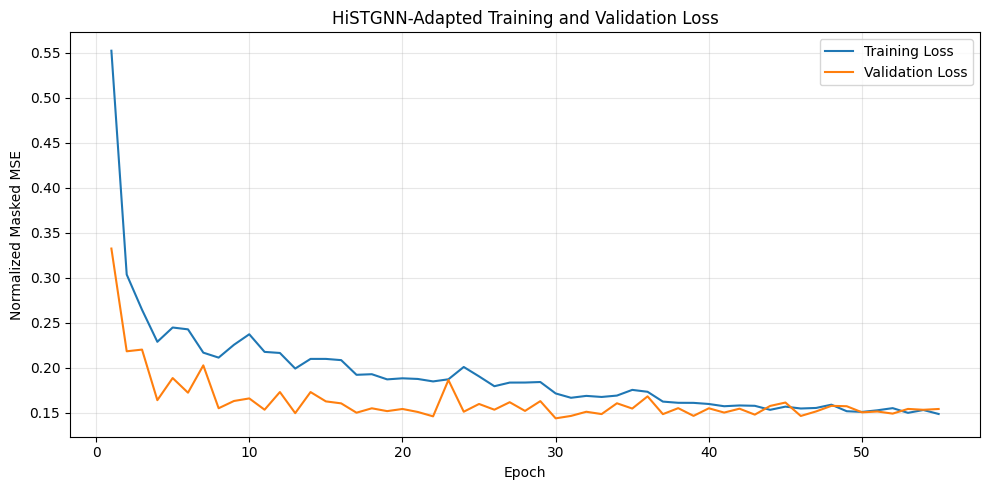

In [52]:
# ============================================================
# CELL 26: TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

epochs_ran = len(history["train_loss"])

epochs_axis = range(
    1,
    epochs_ran + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_axis,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_axis,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized Masked MSE")
plt.title("HiSTGNN-Adapted Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

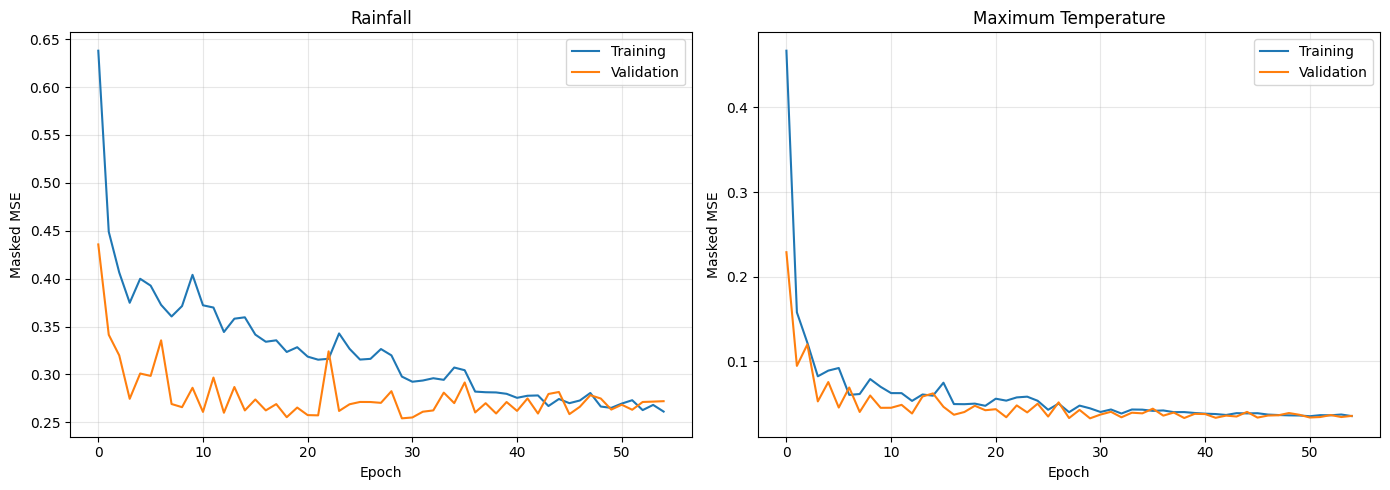

In [53]:
# ============================================================
# CELL 27: VARIABLE-SPECIFIC LOSS CURVES
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5)
)

# ------------------------------------------------------------
# Rainfall
# ------------------------------------------------------------

axes[0].plot(
    history["train_rainfall_loss"],
    label="Training"
)

axes[0].plot(
    history["val_rainfall_loss"],
    label="Validation"
)

axes[0].set_title("Rainfall")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Masked MSE")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ------------------------------------------------------------
# Temperature
# ------------------------------------------------------------

axes[1].plot(
    history["train_temperature_loss"],
    label="Training"
)

axes[1].plot(
    history["val_temperature_loss"],
    label="Validation"
)

axes[1].set_title("Maximum Temperature")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Masked MSE")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
# ============================================================
# CELL 28: LOAD BEST CHECKPOINT
# ============================================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best checkpoint.")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

Loaded best checkpoint.
Best epoch: 30
Best validation loss: 0.14352140327294668


In [55]:
# ============================================================
# CELL 29: TEST EVALUATION METRICS
# ============================================================

def calculate_metrics(
    prediction,
    target,
    mask
):
    """
    Inputs are physical-unit values:
        prediction: [N, 2]
        target: [N, 2]
        mask: [N, 2]

    Returns metrics separately for rainfall and temperature.
    """

    results = {}

    variable_names = [
        "Rainfall",
        "Maximum Temperature"
    ]

    for variable in range(2):

        valid = mask[:, variable].astype(bool)

        pred_valid = prediction[
            valid, variable
        ]

        target_valid = target[
            valid, variable
        ]

        error = pred_valid - target_valid

        mae = np.mean(
            np.abs(error)
        )

        rmse = np.sqrt(
            np.mean(error ** 2)
        )

        bias = np.mean(error)

        ss_res = np.sum(
            error ** 2
        )

        ss_tot = np.sum(
            (target_valid - target_valid.mean()) ** 2
        )

        r2 = (
            1.0 - ss_res / ss_tot
            if ss_tot > 0
            else np.nan
        )

        results[variable_names[variable]] = {
            "N": len(target_valid),
            "MAE": mae,
            "RMSE": rmse,
            "Bias": bias,
            "R2": r2
        }

    return results


def print_metrics(
    results,
    title
):

    print("\n" + "=" * 75)
    print(title)
    print("=" * 75)

    for variable, metrics in results.items():

        print(f"\n{variable}")

        for key, value in metrics.items():

            if key == "N":
                print(f"{key}: {value}")
            else:
                print(
                    f"{key}: {value:.6f}"
                )

In [56]:
# ============================================================
# CELL 30: GENERATE TEST PREDICTIONS
# ============================================================

model.eval()

test_predictions_norm = []

with torch.no_grad():

    for idx in range(len(X_test_np)):

        x = torch.from_numpy(
            X_test_np[idx:idx+1]
        ).to(
            DEVICE,
            dtype=torch.float32
        )

        prediction_norm = model(x)

        prediction_norm = (
            prediction_norm
            .squeeze(0)
            .cpu()
            .numpy()
        )

        test_predictions_norm.append(
            prediction_norm
        )

test_predictions_norm = np.stack(
    test_predictions_norm,
    axis=0
)

print(
    "Normalized prediction shape:",
    test_predictions_norm.shape
)

assert test_predictions_norm.shape == (
    2,
    5040,
    2
)

# ------------------------------------------------------------
# Inverse normalization
# ------------------------------------------------------------

test_predictions = (
    test_predictions_norm
    * target_std.numpy()[None, None, :]
    + target_mean.numpy()[None, None, :]
)

print(
    "Physical prediction shape:",
    test_predictions.shape
)

print("\nRainfall prediction range:")
print(
    test_predictions[..., 0].min(),
    test_predictions[..., 0].max()
)

print("\nTemperature prediction range:")
print(
    test_predictions[..., 1].min(),
    test_predictions[..., 1].max()
)

Normalized prediction shape: (2, 5040, 2)
Physical prediction shape: (2, 5040, 2)

Rainfall prediction range:
0.5281832 15.515029

Temperature prediction range:
20.996708 34.09451


In [57]:
# ============================================================
# CELL 31: PER-YEAR TEST RESULTS
# ============================================================

test_years = test_data["target_years"]

annual_results = {}

for i, year in enumerate(test_years):

    predictions_year = test_predictions[i]

    targets_year = Y_test_np[i]

    masks_year = M_test_np[i]

    results_year = calculate_metrics(
        predictions_year,
        targets_year,
        masks_year
    )

    annual_results[int(year)] = results_year

    print_metrics(
        results_year,
        f"TEST RESULTS — {year}"
    )


TEST RESULTS — 2024

Rainfall
N: 4736
MAE: 0.586859
RMSE: 0.858829
Bias: -0.057974
R2: 0.842608

Maximum Temperature
N: 4476
MAE: 0.488116
RMSE: 0.756483
Bias: -0.158751
R2: 0.927336

TEST RESULTS — 2025

Rainfall
N: 4736
MAE: 0.641416
RMSE: 0.888541
Bias: -0.205334
R2: 0.817239

Maximum Temperature
N: 4476
MAE: 0.442411
RMSE: 0.567549
Bias: 0.221007
R2: 0.954792


In [58]:
# ============================================================
# CELL 32: COMBINED TEST RESULTS
# ============================================================

combined_predictions = test_predictions.reshape(
    -1,
    2
)

combined_targets = Y_test_np.reshape(
    -1,
    2
)

combined_masks = M_test_np.reshape(
    -1,
    2
)

combined_results = calculate_metrics(
    combined_predictions,
    combined_targets,
    combined_masks
)

print_metrics(
    combined_results,
    "COMBINED TEST RESULTS — 2024–2025"
)


COMBINED TEST RESULTS — 2024–2025

Rainfall
N: 9472
MAE: 0.614138
RMSE: 0.873811
Bias: -0.131654
R2: 0.830722

Maximum Temperature
N: 8952
MAE: 0.465263
RMSE: 0.668722
Bias: 0.031128
R2: 0.940616


In [59]:
# ============================================================
# CELL 33: PERSISTENCE BASELINE
# ============================================================

# The first two input features are normalized rainfall
# and normalized maximum temperature.

last_input_normalized = X_test_np[
    :, -1, :, :2
]

# Inverse normalization
persistence_predictions = (
    last_input_normalized
    * target_std.numpy()[None, None, :]
    + target_mean.numpy()[None, None, :]
)

print(
    "Persistence prediction shape:",
    persistence_predictions.shape
)

# ------------------------------------------------------------
# Per-year persistence metrics
# ------------------------------------------------------------

for i, year in enumerate(test_years):

    persistence_year_results = calculate_metrics(
        persistence_predictions[i],
        Y_test_np[i],
        M_test_np[i]
    )

    print_metrics(
        persistence_year_results,
        f"PERSISTENCE BASELINE — {year}"
    )

# ------------------------------------------------------------
# Combined persistence results
# ------------------------------------------------------------

persistence_combined_results = calculate_metrics(
    persistence_predictions.reshape(-1, 2),
    Y_test_np.reshape(-1, 2),
    M_test_np.reshape(-1, 2)
)

print_metrics(
    persistence_combined_results,
    "COMBINED PERSISTENCE — 2024–2025"
)

Persistence prediction shape: (2, 5040, 2)

PERSISTENCE BASELINE — 2024

Rainfall
N: 4736
MAE: 0.683630
RMSE: 0.968006
Bias: -0.356693
R2: 0.800049

Maximum Temperature
N: 4476
MAE: 0.538356
RMSE: 0.774625
Bias: -0.088517
R2: 0.923809

PERSISTENCE BASELINE — 2025

Rainfall
N: 4736
MAE: 0.596028
RMSE: 0.812037
Bias: -0.173093
R2: 0.847356

Maximum Temperature
N: 4476
MAE: 0.379472
RMSE: 0.434544
Bias: 0.347473
R2: 0.973498

COMBINED PERSISTENCE — 2024–2025

Rainfall
N: 9472
MAE: 0.639829
RMSE: 0.893431
Bias: -0.264893
R2: 0.823034

Maximum Temperature
N: 8952
MAE: 0.458914
RMSE: 0.628042
Bias: 0.129478
R2: 0.947621


In [60]:
# ============================================================
# CELL 34: COMPARISON TABLE
# ============================================================

import pandas as pd

comparison_rows = []

for variable in [
    "Rainfall",
    "Maximum Temperature"
]:

    for metric in [
        "MAE",
        "RMSE",
        "Bias",
        "R2"
    ]:

        comparison_rows.append({
            "Variable": variable,
            "Metric": metric,
            "HiSTGNN_Adapted": (
                combined_results[variable][metric]
            ),
            "Persistence": (
                persistence_combined_results[variable][metric]
            )
        })

comparison_df = pd.DataFrame(
    comparison_rows
)

comparison_df["Improvement_%"] = (
    (
        comparison_df["Persistence"]
        - comparison_df["HiSTGNN_Adapted"]
    )
    /
    comparison_df["Persistence"].abs()
) * 100

display(
    comparison_df.round(4)
)

,Variable,Metric,HiSTGNN_Adapted,Persistence,Improvement_%
0,Rainfall,MAE,0.6141,0.6398,4.015300
1,Rainfall,RMSE,0.8738,0.8934,2.196000
2,Rainfall,Bias,-0.1317,-0.2649,-50.299198
3,Rainfall,R2,0.8307,0.8230,-0.934000
4,Maximum Temperature,MAE,0.4653,0.4589,-1.383600
5,Maximum Temperature,RMSE,0.6687,0.6280,-6.477300
6,Maximum Temperature,Bias,0.0311,0.1295,75.958900
7,Maximum Temperature,R2,0.9406,0.9476,0.739200


In [61]:
# ============================================================
# CELL 35: EXTENDED TRAINING CONFIGURATION
# ============================================================

EXTENDED_CONFIG = {
    "epochs": 300,
    "patience": 40,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "gradient_clip": 1.0,
    "min_delta": 1e-5,
}

ORIGINAL_CHECKPOINT = "/kaggle/working/histgnn_adapted_best.pt"

EXTENDED_CHECKPOINT = "/kaggle/working/histgnn_adapted_extended_best.pt"

print("Original checkpoint:", ORIGINAL_CHECKPOINT)
print("Extended checkpoint:", EXTENDED_CHECKPOINT)
print("\nExtended configuration:")
print(EXTENDED_CONFIG)

Original checkpoint: /kaggle/working/histgnn_adapted_best.pt
Extended checkpoint: /kaggle/working/histgnn_adapted_extended_best.pt

Extended configuration:
{'epochs': 300, 'patience': 40, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'gradient_clip': 1.0, 'min_delta': 1e-05}


In [62]:
# ============================================================
# CELL 35: EXTENDED TRAINING CONFIGURATION
# ============================================================

EXTENDED_CONFIG = {
    "epochs": 300,
    "patience": 40,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "gradient_clip": 1.0,
    "min_delta": 1e-5,
}

ORIGINAL_CHECKPOINT = "/kaggle/working/histgnn_adapted_best.pt"

EXTENDED_CHECKPOINT = "/kaggle/working/histgnn_adapted_extended_best.pt"

print("Original checkpoint:", ORIGINAL_CHECKPOINT)
print("Extended checkpoint:", EXTENDED_CHECKPOINT)
print("\nExtended configuration:")
print(EXTENDED_CONFIG)

Original checkpoint: /kaggle/working/histgnn_adapted_best.pt
Extended checkpoint: /kaggle/working/histgnn_adapted_extended_best.pt

Extended configuration:
{'epochs': 300, 'patience': 40, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'gradient_clip': 1.0, 'min_delta': 1e-05}


In [64]:
# ============================================================
# CELL 37: EXTENDED TRAINING (SELF-CONTAINED FIX)
# ============================================================

# ------------------------------------------------------------
# 1. Load original best checkpoint
# ------------------------------------------------------------

original_checkpoint = torch.load(
    ORIGINAL_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    original_checkpoint["model_state_dict"]
)

# ------------------------------------------------------------
# 2. Initialize optimizer and restore optimizer state
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=EXTENDED_CONFIG["learning_rate"],
    weight_decay=EXTENDED_CONFIG["weight_decay"]
)

if "optimizer_state_dict" in original_checkpoint:

    optimizer.load_state_dict(
        original_checkpoint["optimizer_state_dict"]
    )

# ------------------------------------------------------------
# 3. Initialize scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=8,
    min_lr=1e-5
)

# ------------------------------------------------------------
# 4. Initialize extended-training variables
# ------------------------------------------------------------

best_val_loss_extended = float(
    original_checkpoint["best_val_loss"]
)

best_epoch_extended = int(
    original_checkpoint["epoch"]
)

best_state_extended = copy.deepcopy(
    original_checkpoint["model_state_dict"]
)

epochs_without_improvement_extended = 0

extended_history = {
    "train_loss": [],
    "train_rainfall_loss": [],
    "train_temperature_loss": [],
    "val_loss": [],
    "val_rainfall_loss": [],
    "val_temperature_loss": [],
    "learning_rate": []
}

print("Extended training initialized.")

print("Starting checkpoint epoch:",
      best_epoch_extended)

print("Starting reference validation loss:",
      best_val_loss_extended)

# ------------------------------------------------------------
# 5. Save initial best checkpoint
# ------------------------------------------------------------

torch.save(
    {
        "epoch": best_epoch_extended,
        "model_state_dict": best_state_extended,
        "best_val_loss": best_val_loss_extended,
        "model_config": MODEL_CONFIG,
        "train_config": EXTENDED_CONFIG,
        "history": extended_history,
        "continued_from_epoch": 30
    },
    EXTENDED_CHECKPOINT
)

# ------------------------------------------------------------
# 6. Extended training
# ------------------------------------------------------------

start_time_extended = time.time()

for epoch in range(31, EXTENDED_CONFIG["epochs"] + 1):

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_losses = []
    train_rain_losses = []
    train_temp_losses = []

    train_order = np.random.permutation(
        len(X_train_np)
    )

    for idx in train_order:

        x, y, mask = prepare_sample(
            X_train_np,
            Y_train_np,
            M_train_np,
            idx
        )

        optimizer.zero_grad(set_to_none=True)

        prediction = model(x)

        (
            loss,
            rainfall_loss,
            temperature_loss
        ) = masked_mse_per_variable(
            prediction,
            y,
            mask
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            EXTENDED_CONFIG["gradient_clip"]
        )

        optimizer.step()

        train_losses.append(loss.item())
        train_rain_losses.append(rainfall_loss.item())
        train_temp_losses.append(temperature_loss.item())

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_losses = []
    val_rain_losses = []
    val_temp_losses = []

    with torch.no_grad():

        for idx in range(len(X_val_np)):

            x, y, mask = prepare_sample(
                X_val_np,
                Y_val_np,
                M_val_np,
                idx
            )

            prediction = model(x)

            (
                loss,
                rainfall_loss,
                temperature_loss
            ) = masked_mse_per_variable(
                prediction,
                y,
                mask
            )

            val_losses.append(loss.item())
            val_rain_losses.append(rainfall_loss.item())
            val_temp_losses.append(temperature_loss.item())

    # ========================================================
    # AGGREGATE
    # ========================================================

    train_loss = np.mean(train_losses)
    train_rain_loss = np.mean(train_rain_losses)
    train_temp_loss = np.mean(train_temp_losses)

    val_loss = np.mean(val_losses)
    val_rain_loss = np.mean(val_rain_losses)
    val_temp_loss = np.mean(val_temp_losses)

    current_lr = optimizer.param_groups[0]["lr"]

    extended_history["train_loss"].append(train_loss)
    extended_history["train_rainfall_loss"].append(train_rain_loss)
    extended_history["train_temperature_loss"].append(train_temp_loss)

    extended_history["val_loss"].append(val_loss)
    extended_history["val_rainfall_loss"].append(val_rain_loss)
    extended_history["val_temperature_loss"].append(val_temp_loss)

    extended_history["learning_rate"].append(current_lr)

    # Scheduler
    scheduler.step(val_loss)

    # ========================================================
    # CHECKPOINT IMPROVEMENT
    # ========================================================

    if val_loss < best_val_loss_extended - EXTENDED_CONFIG["min_delta"]:

        best_val_loss_extended = val_loss
        best_epoch_extended = epoch

        best_state_extended = copy.deepcopy(
            model.state_dict()
        )

        epochs_without_improvement_extended = 0

        torch.save(
            {
                "epoch": best_epoch_extended,
                "model_state_dict": best_state_extended,
                "best_val_loss": best_val_loss_extended,
                "model_config": MODEL_CONFIG,
                "train_config": EXTENDED_CONFIG,
                "history": extended_history,
                "continued_from_epoch": 30
            },
            EXTENDED_CHECKPOINT
        )

        improved = " *BEST*"

    else:

        epochs_without_improvement_extended += 1

        improved = ""

    # ========================================================
    # LOGGING
    # ========================================================

    if (
        epoch == 31
        or epoch % 5 == 0
        or improved == " *BEST*"
    ):

        print(
            f"Epoch {epoch:03d}/{EXTENDED_CONFIG['epochs']} | "
            f"Train: {train_loss:.5f} | "
            f"Val: {val_loss:.5f} | "
            f"Rain Val: {val_rain_loss:.5f} | "
            f"Temp Val: {val_temp_loss:.5f} | "
            f"LR: {current_lr:.2e} | "
            f"No improvement: "
            f"{epochs_without_improvement_extended}"
            f"{improved}"
        )

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if (
        epochs_without_improvement_extended
        >= EXTENDED_CONFIG["patience"]
    ):

        print(
            f"\nExtended early stopping at epoch {epoch}"
        )

        break

# ------------------------------------------------------------
# 7. Final extended training report
# ------------------------------------------------------------

extended_training_time = (
    time.time() - start_time_extended
)

print("\n" + "=" * 70)
print("EXTENDED TRAINING COMPLETE")
print("=" * 70)

print(
    "Original best validation loss:",
    original_checkpoint["best_val_loss"]
)

print(
    "Extended best validation loss:",
    best_val_loss_extended
)

print(
    "Best epoch:",
    best_epoch_extended
)

print(
    "Extended training time:",
    round(extended_training_time / 60, 2),
    "minutes"
)

print(
    "Checkpoint saved:",
    os.path.exists(EXTENDED_CHECKPOINT)
)

Extended training initialized.
Starting checkpoint epoch: 30
Starting reference validation loss: 0.14352140327294668
Epoch 031/300 | Train: 0.17553 | Val: 0.15081 | Rain Val: 0.26755 | Temp Val: 0.03407 | LR: 1.00e-03 | No improvement: 1
Epoch 035/300 | Train: 0.16086 | Val: 0.14732 | Rain Val: 0.25924 | Temp Val: 0.03540 | LR: 1.00e-03 | No improvement: 5
Epoch 040/300 | Train: 0.16319 | Val: 0.16242 | Rain Val: 0.28586 | Temp Val: 0.03898 | LR: 1.00e-03 | No improvement: 10
Epoch 045/300 | Train: 0.15893 | Val: 0.15208 | Rain Val: 0.26413 | Temp Val: 0.04003 | LR: 1.00e-03 | No improvement: 15
Epoch 050/300 | Train: 0.15138 | Val: 0.15331 | Rain Val: 0.27027 | Temp Val: 0.03635 | LR: 5.00e-04 | No improvement: 20
Epoch 055/300 | Train: 0.15200 | Val: 0.15056 | Rain Val: 0.26607 | Temp Val: 0.03505 | LR: 5.00e-04 | No improvement: 25
Epoch 060/300 | Train: 0.14558 | Val: 0.15506 | Rain Val: 0.27411 | Temp Val: 0.03601 | LR: 2.50e-04 | No improvement: 30
Epoch 065/300 | Train: 0.14622 

In [65]:
# ============================================================
# CELL 38: SELECT FINAL CHECKPOINT USING VALIDATION PERFORMANCE
# ============================================================

original_best = float(
    original_checkpoint["best_val_loss"]
)

extended_best = float(
    best_val_loss_extended
)

print("Original best validation loss:", original_best)
print("Extended best validation loss:", extended_best)

if extended_best < original_best:

    FINAL_CHECKPOINT = EXTENDED_CHECKPOINT

    print("\nDecision: EXTENDED checkpoint selected.")
    print("Validation improvement:", original_best - extended_best)

else:

    FINAL_CHECKPOINT = ORIGINAL_CHECKPOINT

    print("\nDecision: ORIGINAL checkpoint retained.")
    print("Extended run did not improve validation performance.")

# ------------------------------------------------------------
# Load selected checkpoint
# ------------------------------------------------------------

final_checkpoint = torch.load(
    FINAL_CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(
    final_checkpoint["model_state_dict"]
)

model.eval()

print("\nFinal checkpoint:", FINAL_CHECKPOINT)
print("Selected epoch:", final_checkpoint["epoch"])
print("Selected validation loss:", final_checkpoint["best_val_loss"])

Original best validation loss: 0.14352140327294668
Extended best validation loss: 0.14352140327294668

Decision: ORIGINAL checkpoint retained.
Extended run did not improve validation performance.

Final checkpoint: /kaggle/working/histgnn_adapted_best.pt
Selected epoch: 30
Selected validation loss: 0.14352140327294668


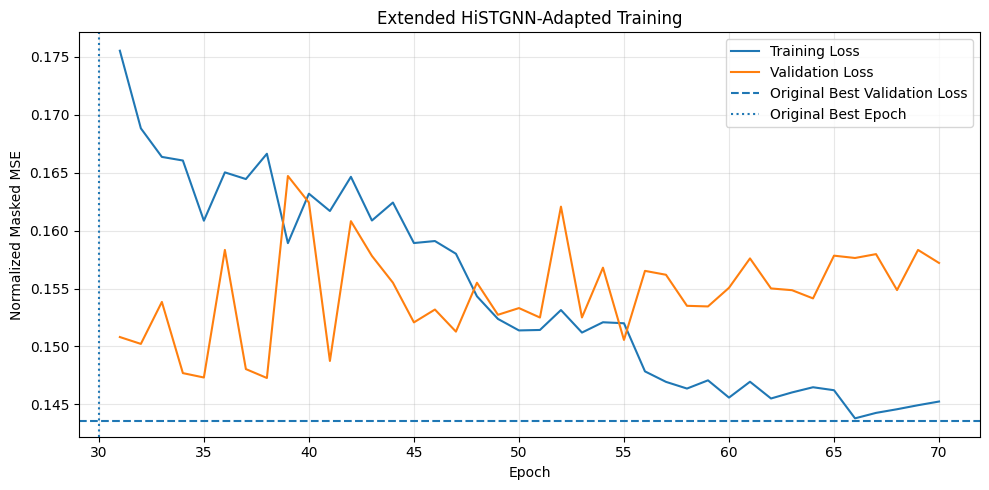

In [66]:
# ============================================================
# CELL 39: EXTENDED TRAINING CURVES
# ============================================================

import matplotlib.pyplot as plt

extended_epochs = range(
    31,
    31 + len(extended_history["train_loss"])
)

plt.figure(figsize=(10, 5))

plt.plot(
    extended_epochs,
    extended_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    extended_epochs,
    extended_history["val_loss"],
    label="Validation Loss"
)

plt.axhline(
    original_best,
    linestyle="--",
    label="Original Best Validation Loss"
)

plt.axvline(
    30,
    linestyle=":",
    label="Original Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized Masked MSE")
plt.title("Extended HiSTGNN-Adapted Training")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()